# HELDOUT evaluation — trained on 336 h (Jul+Aug+Sep 2019)

The data-scaling future-transfer model **ft_336** (trained on Jul+Aug+Sep, 336h of 2019)
applied, with no retraining, to **all 15 held-out days** not used in any training: three
Jan 2019 winter episodes (2-5, 8-9, 22-23 Jan), two further Oct 2019 episodes (11-12, 16-17
Oct) and the two Sep 2020 episodes (4-6, 6-8 Sep). None of these were seen in training.
(Oct 29-31 excluded: upstream data error.)
Normalisation uses the model's training statistics. Metrics: pooled RMSE (physical ug/m3) and
mean per-level pattern correlation r, on valid cells, reported per simulated day. Precomputed
in `outputs/heldout_eval_ft_336.json`.

## Per-day metrics (all 15 held-out days)

In [1]:
import json, numpy as np
D=json.load(open('../../outputs/heldout_eval_ft_336.json'))
print(f'model: {D["model"]}   (future-transfer, trained on 2019 only)\n')
print(f'{"episode":>9} {"yr/season":>10} {"day":>4} {"n":>4} {"RMSE":>8} {"r":>7}')
print('-'*48)
for sim,ep in D['episodes'].items():
    tag='2020 Sep' if ep['is2020'] else ('2019 win' if ep['label'].startswith('Jan') else '2019 Oct')
    for day,m in ep['days'].items():
        print(f'{ep["label"]:>9} {tag:>10} {day:>4} {m["n"]:>4} {m["rmse"]:>8.3f} {m["r"]:>7.3f}')
    o=ep['overall']; print(f'{ep["label"]:>9} {tag:>10} {"all":>4} {"":>4} {o["rmse"]:>8.3f} {o["r"]:>7.3f}')
    print('-'*48)
oa=D['overall_all']
print(f'{"ALL HELDOUT":>9} {"(15 days)":>10} {"":>4} {"":>4} {oa["rmse"]:>8.3f} {oa["r"]:>7.3f}   <- pooled over all held-out days')
# 2020-only pooled
s=c=0.0; rr=[]
for sim,ep in D['episodes'].items():
    if ep['is2020']:
        for day,m in ep['days'].items(): rr+= [m['r']]*m['n']
b=D['best']; b20=D['best2020']
print(f'\nbest overall : {b["label"]} h{b["hour"]}  r={b["r"]:.3f} RMSE={b["rmse"]:.3f}')
print(f'best in 2020 : {b20["label"]} h{b20["hour"]}  r={b20["r"]:.3f} RMSE={b20["rmse"]:.3f}')

model: ft_336   (future-transfer, trained on 2019 only)

  episode  yr/season  day    n     RMSE       r
------------------------------------------------
    Jan02   2019 win    1  288    2.407   0.721
    Jan02   2019 win    2  288    7.349   0.524
    Jan02   2019 win    3  288    9.406   0.497
    Jan02   2019 win    4  288    5.172   0.693
    Jan02   2019 win  all         6.615   0.609
------------------------------------------------
    Jan08   2019 win    1  288    1.065   0.840
    Jan08   2019 win    2  288    0.973   0.812
    Jan08   2019 win  all         1.020   0.826
------------------------------------------------
    Jan22   2019 win    1  288    2.232   0.706
    Jan22   2019 win    2  288    6.239   0.557
    Jan22   2019 win  all         4.686   0.632
------------------------------------------------
    Oct11   2019 Oct    1  288    0.424   0.905
    Oct11   2019 Oct  all         0.424   0.905
------------------------------------------------
    Oct16   2019 Oct    1 

## Per-episode summary

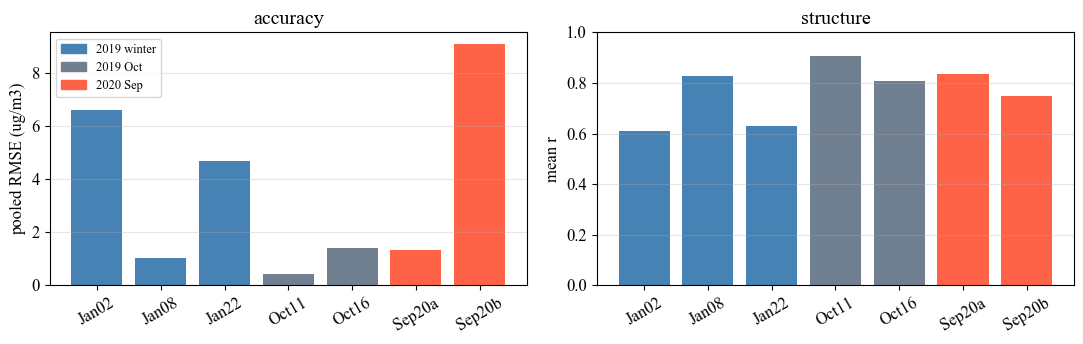

In [2]:
import matplotlib as _mpl, matplotlib.pyplot as plt
_mpl.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','Nimbus Roman','DejaVu Serif'],
    'mathtext.fontset':'stix','axes.unicode_minus':False,'font.size':12})
labs=[ep['label'] for ep in D['episodes'].values()]
rm=[ep['overall']['rmse'] for ep in D['episodes'].values()]
rr=[ep['overall']['r'] for ep in D['episodes'].values()]
cols=['tomato' if ep['is2020'] else ('steelblue' if ep['label'].startswith('Jan') else 'slategray') for ep in D['episodes'].values()]
fig,ax=plt.subplots(1,2,figsize=(11,3.6))
ax[0].bar(labs,rm,color=cols); ax[0].set_ylabel('pooled RMSE (ug/m3)'); ax[0].set_title('accuracy')
ax[1].bar(labs,rr,color=cols); ax[1].set_ylabel('mean r'); ax[1].set_ylim(0,1); ax[1].set_title('structure')
for a in ax: a.grid(True,alpha=0.3,axis='y'); a.tick_params(axis='x',rotation=30)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color='steelblue',label='2019 winter'),Patch(color='slategray',label='2019 Oct'),Patch(color='tomato',label='2020 Sep')],fontsize=9)
plt.tight_layout(); plt.show()

## Best held-out example (highest mean-r across all 15 days)

In [3]:
import sys, os; sys.path.insert(0,'../../src')
import torch
from matplotlib.gridspec import GridSpec
from dataloader import PALMDatasetV2
from model import UNet3DFiLM
NZ=12; ZH=[15,25,35,45,55,75,95,115,135,155,175,195]
dev=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ck=torch.load('../../outputs/future_transfer_mask/checkpoints/best.pt',map_location='cpu',weights_only=False)
model=UNet3DFiLM(in_ch=19,spatial_ch=3,base_ch=16,dropout=0.0,n_z=NZ,use_attention=True,n_down=4)
model.load_state_dict(ck['model_state_dict']); model.to(dev).eval(); st=ck['norm_stats']
mean=torch.tensor(st['pm25']['mean'][:NZ]).view(-1,1,1); std=torch.tensor(st['pm25']['std'][:NZ]).view(-1,1,1)
def plot_best(rec, fname, tag):
    sim=rec['episode']; nh=D['episodes'][sim]['n_hours']
    ds=PALMDatasetV2(sims=[sim],mask_input=True,normalise=True,hour_filter={sim:set(range(1,nh+1))},
                     global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); ds._stats=st
    x,y,mk=ds[rec['idx']]; mask=mk.numpy().astype(bool)
    t=ds._index[rec['idx']][4]
    with torch.no_grad(): out=model(x.unsqueeze(0).to(dev)).cpu()[0]
    truth=torch.expm1(y*std+mean).numpy(); pred=torch.expm1(out*std+mean).numpy()
    rel=100.0*(pred-truth)/np.where(truth>1e-6,truth,np.nan)
    levels=list(range(NZ)); npr=2; nrows=(len(levels)+npr-1)//npr
    wr=[]; blocks=[]; ci=0
    for L in range(npr):
        blocks.append((ci,ci+1,ci+2,ci+4,ci+5)); wr+=[1,1,0.06,0.16,1,0.06]; ci+=6
        if L<npr-1: wr+=[0.38]; ci+=1
    fig=plt.figure(figsize=(14,2.35*nrows))
    gs=GridSpec(nrows,len(wr),width_ratios=wr,wspace=0.05,hspace=0.30)
    for i,z in enumerate(levels):
        r=i//npr; L=i%npr; ct,cp,cc1,ce,cc2=blocks[L]
        axt=fig.add_subplot(gs[r,ct]); axp=fig.add_subplot(gs[r,cp]); axc1=fig.add_subplot(gs[r,cc1])
        axe=fig.add_subplot(gs[r,ce]); axc2=fig.add_subplot(gs[r,cc2])
        ti=np.where(mask[z],truth[z],np.nan); pi=np.where(mask[z],pred[z],np.nan); ei=np.where(mask[z],rel[z],np.nan)
        if mask[z].sum()>=10:
            a=truth[z][mask[z]]; b=pred[z][mask[z]]
            vmin=min(np.percentile(a,1),np.percentile(b,1)); vmax=max(np.percentile(a,99),np.percentile(b,99))
            el=np.nanpercentile(np.abs(ei),98)+1e-9
        else: vmin,vmax,el=0.0,1.0,1.0
        imt=axt.imshow(ti,cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        axp.imshow(pi,cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        ime=axe.imshow(ei,cmap='RdBu_r',vmin=-el,vmax=el,origin='lower')
        for a in (axt,axp,axe): a.set_xticks([]); a.set_yticks([])
        axt.set_ylabel(f'{ZH[z]} m',fontsize=10)
        if r==0: axt.set_title('PALM'); axp.set_title('prediction'); axe.set_title('rel. err (%)')
        fig.colorbar(imt,cax=axc1); fig.colorbar(ime,cax=axc2)
    fig.suptitle(f"{tag}: {D['episodes'][sim]['label']} {t:%d %b %Y %H:%M}   mean r={rec['r']:.3f}  RMSE={rec['rmse']:.3f} ug/m3",y=1.01)
    os.makedirs('figs',exist_ok=True); fig.savefig(f'figs/{fname}',dpi=200,bbox_inches='tight')
    print('saved figs/'+fname); plt.show()

saved figs/heldout_ft_336_best.png


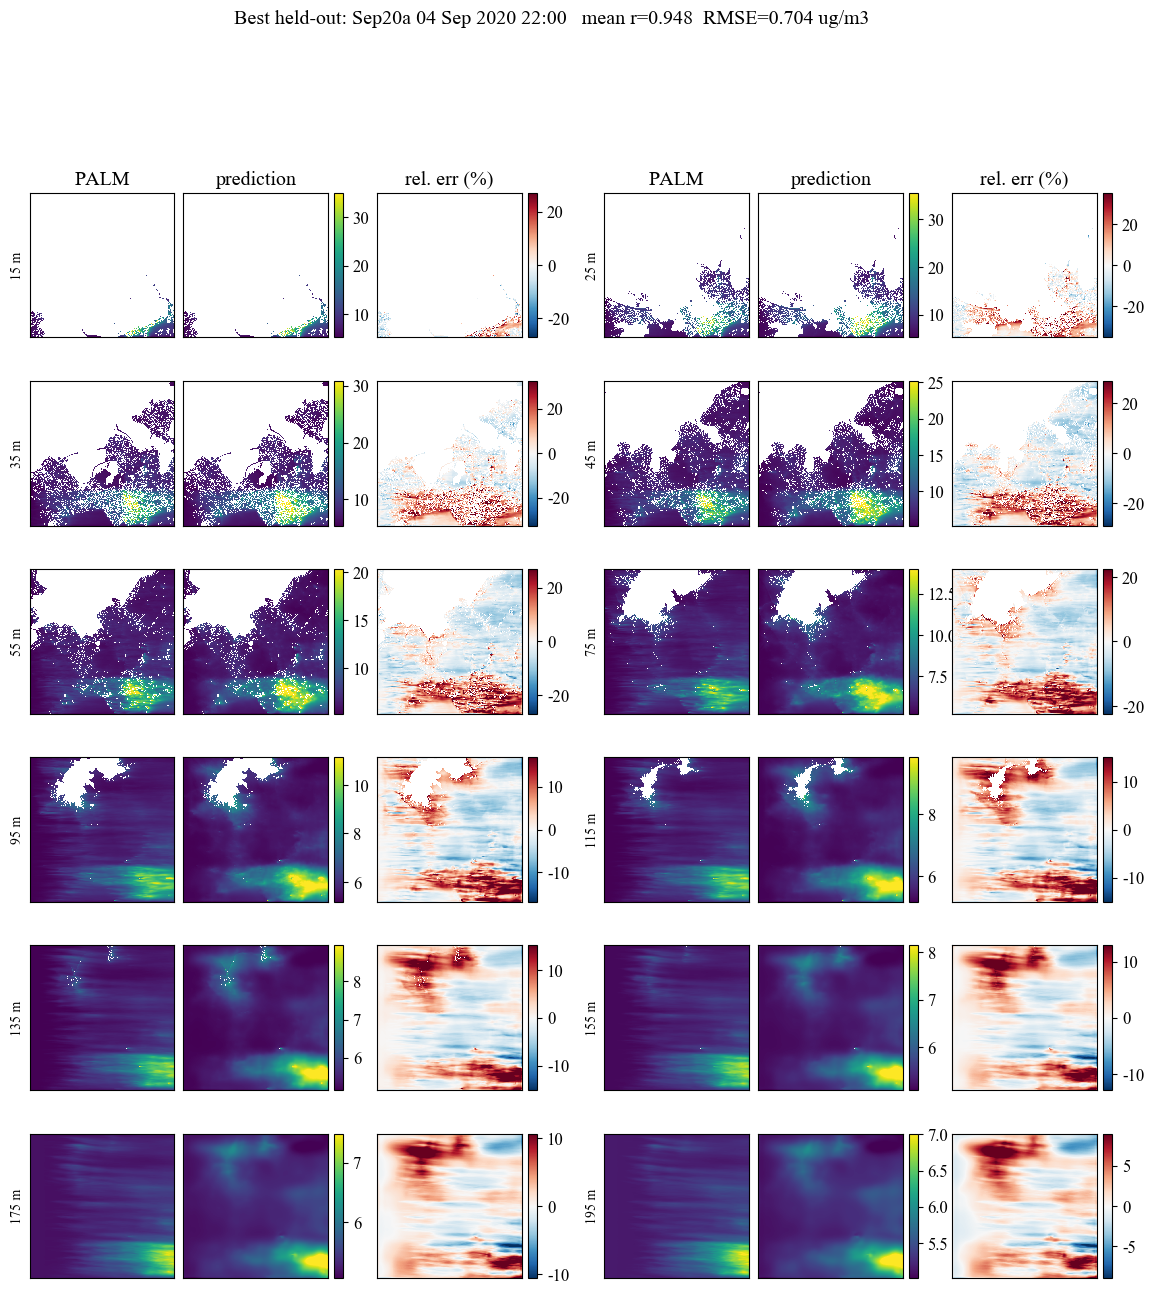

In [4]:
plot_best(D['best'], 'heldout_ft_336_best.png', 'Best held-out')

## Best example within the 2020 test data

saved figs/heldout_ft_336_best2020.png


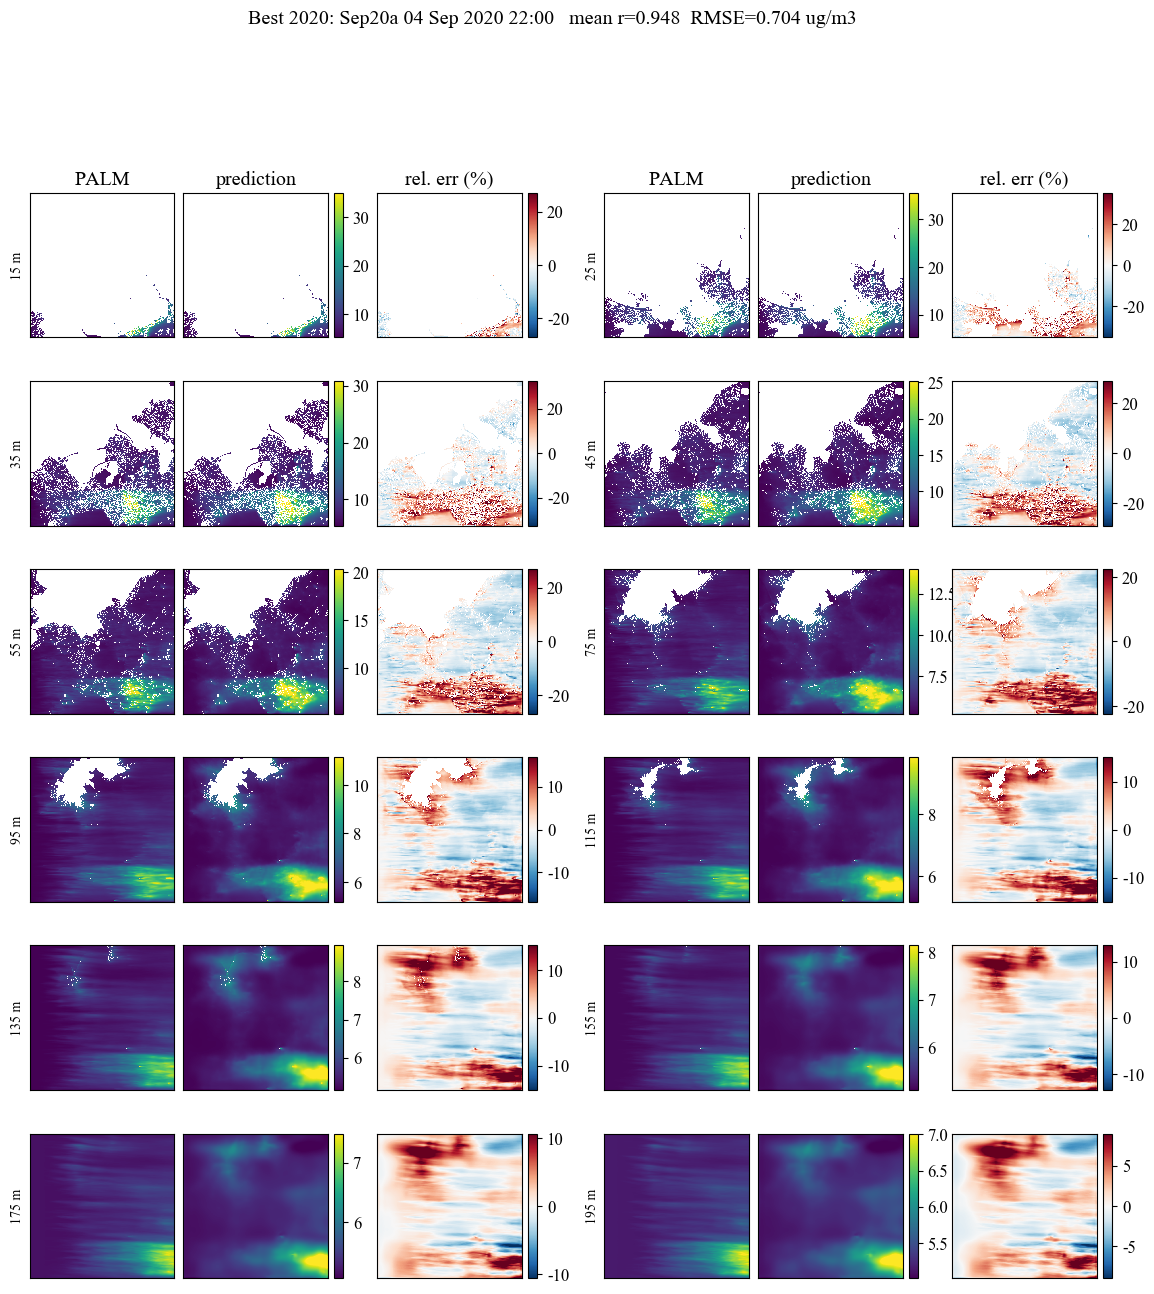

In [5]:
plot_best(D['best2020'], 'heldout_ft_336_best2020.png', 'Best 2020')

## Sep 4 2020 - 3 heights x 6 hours, PALM vs ft_336 prediction (held-out)

Top of each column: time, and the all-level mean r & pooled RMSE for that hour.

saved figs/ft336_sep0420_3heights_truth.png


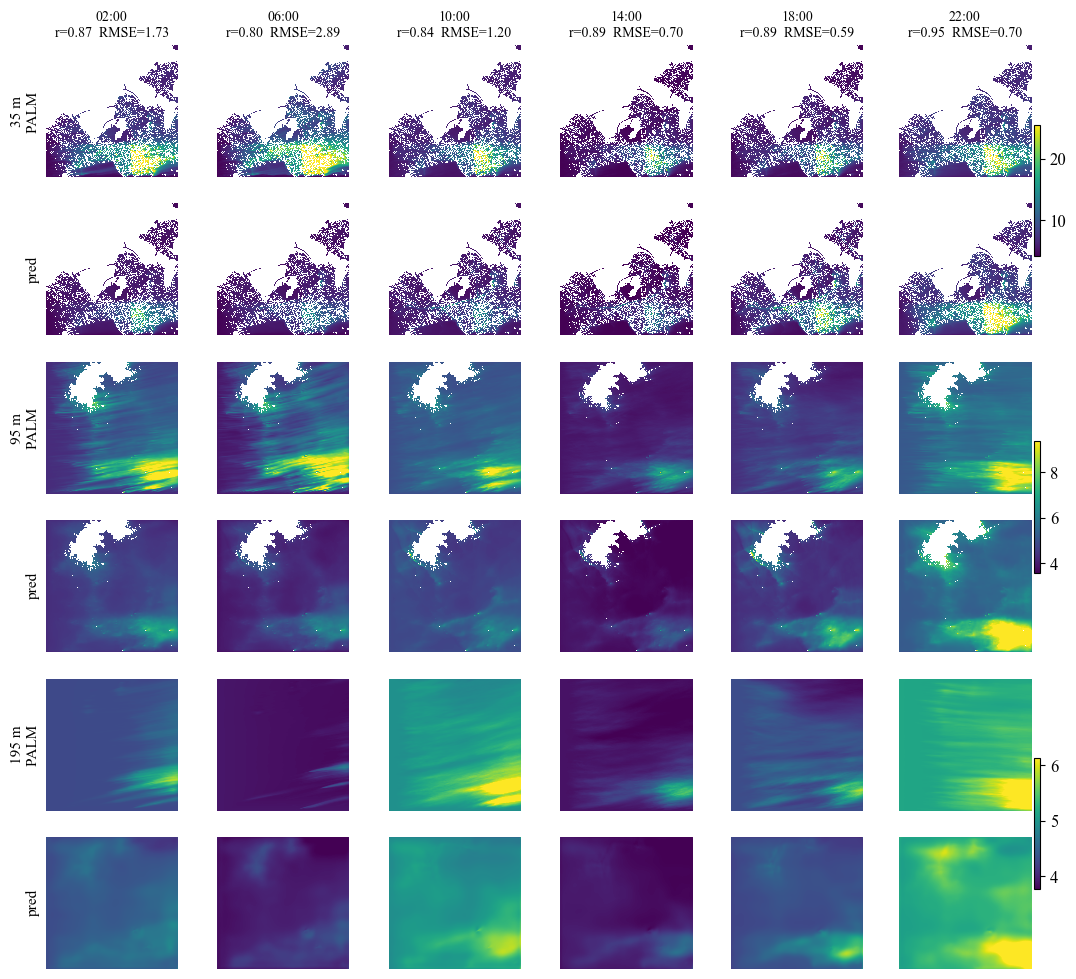

In [6]:
# Sep 4 2020 diurnal with truth: 3 heights x 6 hours, PALM (top) vs ft_336 pred (below)
def pc(a,b):
    am=a-a.mean();bm=b-b.mean();d=np.sqrt((am**2).sum()*(bm**2).sum())
    return float((am*bm).sum()/d) if d>1e-9 else np.nan
SIMA='london_cm20200904-0906'; HRS=[2,6,10,14,18,22]; LVS=[2,6,11]  # 35, 95, 195 m
dsa=PALMDatasetV2(sims=[SIMA],mask_input=True,normalise=True,hour_filter={SIMA:set(range(1,49))},
                  global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); dsa._stats=st
h2i={dsa._index[i][3]:i for i in range(len(dsa))}
P={}; T={}; Mk={}; hr_r={}; hr_rm={}; times={}
with torch.no_grad():
    for h in HRS:
        i=h2i[h]; x,y,mk=dsa[i]; msk=mk.numpy().astype(bool)
        p=torch.expm1(model(x.unsqueeze(0).to(dev)).cpu()[0]*std+mean).numpy(); t=torch.expm1(y*std+mean).numpy()
        P[h]=p; T[h]=t; Mk[h]=msk; times[h]=dsa._index[i][4]
        hr_r[h]=float(np.nanmean([pc(t[z][msk[z]].astype(float),p[z][msk[z]].astype(float)) for z in range(NZ) if msk[z].sum()>10]))
        _sse=0.0; _cnt=0
        for z in range(NZ):
            s=msk[z]
            if s.sum()>10:
                a=t[z][s].astype(np.float64); b=p[z][s].astype(np.float64); _sse+=((b-a)**2).sum(); _cnt+=a.size
        hr_rm[h]=float(np.sqrt(_sse/max(_cnt,1)))
nrow=len(LVS)*2; ncol=len(HRS)
fig,axes=plt.subplots(nrow,ncol,figsize=(ncol*2.15,nrow*2.0)); axes=np.atleast_2d(axes)
for hi,z in enumerate(LVS):
    allv=np.concatenate([np.concatenate([T[h][z][Mk[h][z]],P[h][z][Mk[h][z]]]) for h in HRS if Mk[h][z].sum()>0])
    vmin=float(np.percentile(allv,1)); vmax=float(np.percentile(allv,99))
    rP=2*hi; rp=2*hi+1
    for ci,h in enumerate(HRS):
        for rr,fld,lab in [(rP,T[h][z],'PALM'),(rp,P[h][z],'pred')]:
            ax=axes[rr,ci]; ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_visible(False)
            im=ax.imshow(np.where(Mk[h][z],fld,np.nan),cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
            if rr==0: ax.set_title(f'{times[h]:%H:%M}\nr={hr_r[h]:.2f}  RMSE={hr_rm[h]:.2f}',fontsize=10)
            if ci==0: ax.set_ylabel(f'{ZH[z]} m\nPALM' if lab=='PALM' else 'pred',fontsize=11)
    fig.colorbar(im,ax=[axes[rP,ncol-1],axes[rp,ncol-1]],fraction=0.046,pad=0.02)
import os; os.makedirs('figs',exist_ok=True)
fig.savefig('figs/ft336_sep0420_3heights_truth.png',dpi=300,bbox_inches='tight',pad_inches=0.03)
print('saved figs/ft336_sep0420_3heights_truth.png'); plt.show()

## Best held-out case - results-notebook layout (per-level r & RMSE on top, diff, height on left); 15-75 m and all levels

best held-out case: Sep20a 2020-09-04 22:00  (overall r=0.948, RMSE=0.704)


saved figs/ft336_best_results_to75m.png


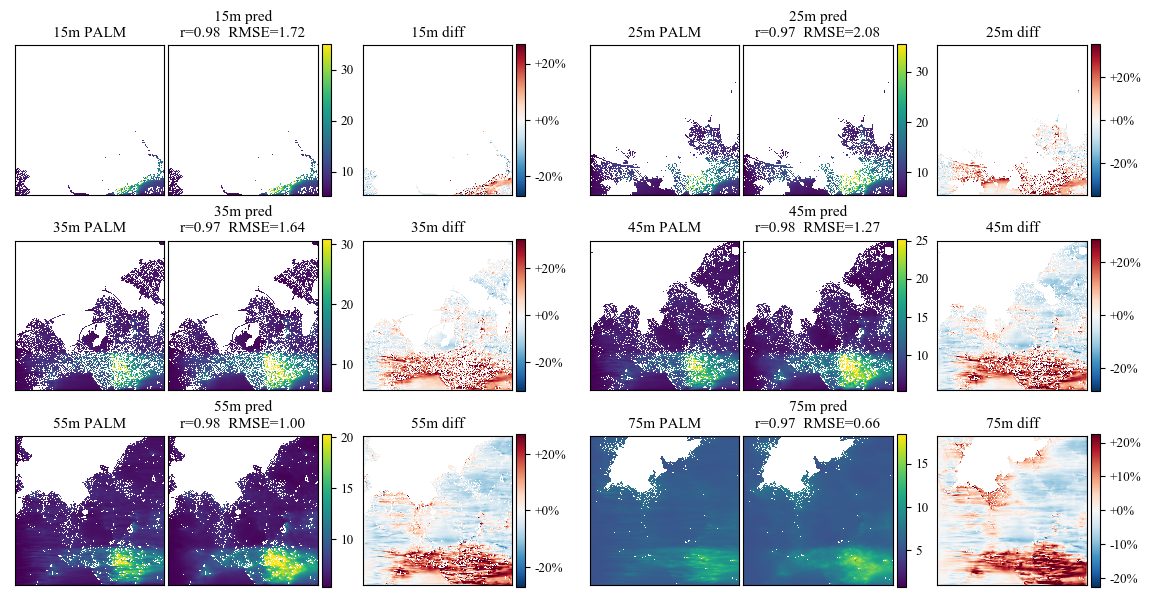

saved figs/ft336_best_results_all.png


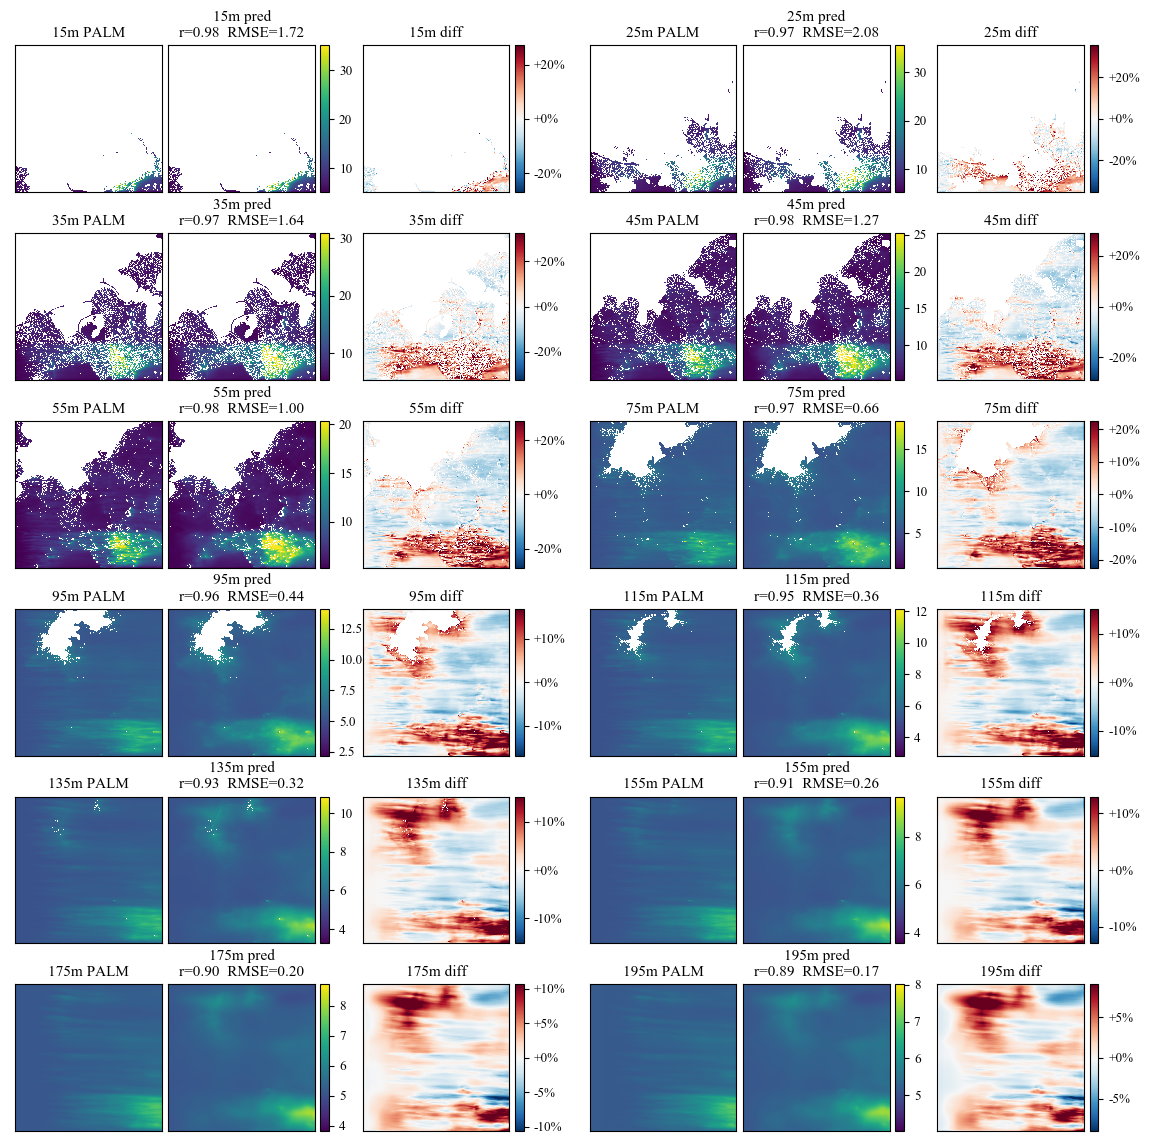

In [7]:
# Best held-out case in the OLD results-notebook layout ("{ZH}m PALM/pred/diff", WIDEN on z>=5) + per-level r & RMSE on pred
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
B=D['best']; simb=B['episode']; nhb=D['episodes'][simb]['n_hours']
dsx=PALMDatasetV2(sims=[simb],mask_input=True,normalise=True,hour_filter={simb:set(range(1,nhb+1))},
                  global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); dsx._stats=st
xb,yb,mkb=dsx[B['idx']]; maskb=mkb.numpy().astype(bool); tb_dt=dsx._index[B['idx']][4]
with torch.no_grad(): ob=model(xb.unsqueeze(0).to(dev)).cpu()[0]
truth=torch.expm1(yb*std+mean).numpy(); pred=torch.expm1(ob*std+mean).numpy()
rel=100.0*(pred-truth)/np.where(truth>1e-6,truth,np.nan)
WIDEN=0.5
def plot_case(levels, fname):
    npr=2; nrows=(len(levels)+npr-1)//npr
    wr=[]; blocks=[]; ci=0
    for L in range(npr):
        blocks.append((ci,ci+1,ci+2,ci+4,ci+5)); wr+=[1,1,0.06,0.16,1,0.06]; ci+=6
        if L<npr-1: wr+=[0.38]; ci+=1
    fig=plt.figure(figsize=(14,2.35*nrows))
    gs=GridSpec(nrows,len(wr),width_ratios=wr,wspace=0.05,hspace=0.28)
    for i,z in enumerate(levels):
        rw=i//npr; L=i%npr; ct,cp,cc1,ce,cc2=blocks[L]
        axt=fig.add_subplot(gs[rw,ct]); axp=fig.add_subplot(gs[rw,cp]); axc1=fig.add_subplot(gs[rw,cc1])
        axe=fig.add_subplot(gs[rw,ce]); axc2=fig.add_subplot(gs[rw,cc2])
        ti=np.where(maskb[z],truth[z],np.nan); pi=np.where(maskb[z],pred[z],np.nan); ei=np.where(maskb[z],rel[z],np.nan)
        if maskb[z].sum()>=10:
            a=truth[z][maskb[z]].astype(float); b=pred[z][maskb[z]].astype(float)
            r=pc(a,b); rm=float(np.sqrt(np.mean((b-a)**2)))
            vmin=min(np.percentile(a,1),np.percentile(b,1)); vmax=max(np.percentile(a,99),np.percentile(b,99))
            if z>=5 and WIDEN>0: s=vmax-vmin; vmin-=WIDEN*s; vmax+=WIDEN*s
            el=np.nanpercentile(np.abs(ei),98)+1e-9
        else: r,rm,vmin,vmax,el=np.nan,np.nan,0.0,1.0,1.0
        imt=axt.imshow(ti,cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        axp.imshow(pi,cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        ime=axe.imshow(ei,cmap='RdBu_r',vmin=-el,vmax=el,origin='lower')
        for ax in (axt,axp,axe): ax.set_xticks([]); ax.set_yticks([])
        axt.set_title(f'{ZH[z]}m PALM',fontsize=11)
        axp.set_title(f'{ZH[z]}m pred\nr={r:.2f}  RMSE={rm:.2f}',fontsize=11)
        axe.set_title(f'{ZH[z]}m diff',fontsize=11)
        fig.colorbar(imt,cax=axc1)
        cb=fig.colorbar(ime,cax=axc2); cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v,p: f'{v:+.0f}%'))
        axc1.tick_params(labelsize=9.5); axc2.tick_params(labelsize=9.5)
    import os; os.makedirs('figs',exist_ok=True)
    fig.savefig('figs/'+fname,dpi=300,bbox_inches='tight'); print('saved figs/'+fname); plt.show()
print(f"best held-out case: {D['episodes'][simb]['label']} {tb_dt:%Y-%m-%d %H:%M}  (overall r={B['r']:.3f}, RMSE={B['rmse']:.3f})")
plot_case(list(range(6)),  'ft336_best_results_to75m.png')
plot_case(list(range(NZ)), 'ft336_best_results_all.png')

## Baseline comparison - Sep 2020a (`london_cm20200904-0906`)

ft_336 vs a **climatology baseline** = the per-cell, per-level mean physical PM2.5 over ft_336's own training set (Jul+Aug+Sep 2019). Both scored on valid cells over all 48 hourly steps: pooled RMSE (ug/m3) and mean per-level pattern correlation r. `RMSE skill` = 1 - RMSE_model / RMSE_clim.

In [8]:
# ft_336 vs climatology baseline on Sep 2020a - summary table
SIMB='london_cm20200904-0906'; NHB=48
_clim=np.load('../../outputs/climatology_ft_336.npy')  # (12,800,800) physical ug/m3, ft_336 training mean
def _pc(a,b):
    am=a-a.mean();bm=b-b.mean();d=np.sqrt((am**2).sum()*(bm**2).sum())
    return float((am*bm).sum()/d) if d>1e-9 else np.nan
_dsb=PALMDatasetV2(sims=[SIMB],mask_input=True,normalise=True,hour_filter={SIMB:set(range(1,NHB+1))},
                   global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); _dsb._stats=st
gm_sse=gm_cnt=0.0; gb_sse=gb_cnt=0.0; gm_rs=[]; gb_rs=[]
with torch.no_grad():
    for i in range(len(_dsb)):
        x,y,mk=_dsb[i]; msk=mk.numpy().astype(bool)
        t=torch.expm1(y*std+mean).numpy()
        p=torch.expm1(model(x.unsqueeze(0).to(dev)).cpu()[0]*std+mean).numpy()
        for z in range(NZ):
            s=msk[z]; a=t[z][s].astype(np.float64)
            if a.size<10 or a.std()<1e-6: continue
            mp=p[z][s].astype(np.float64); cp=_clim[z][s].astype(np.float64)
            gm_sse+=((mp-a)**2).sum(); gm_cnt+=a.size; gm_rs.append(_pc(a,mp))
            gb_sse+=((cp-a)**2).sum(); gb_cnt+=a.size; gb_rs.append(_pc(a,cp))
mR=np.sqrt(gm_sse/gm_cnt); bR=np.sqrt(gb_sse/gb_cnt); mr=np.mean(gm_rs); br=np.mean(gb_rs)
print(f'ft_336 on Sep 2020a  ({NHB} hourly steps, pooled over valid cells)\n')
print(f'{"":22}{"RMSE (ug/m3)":>14}{"mean r":>10}')
print('-'*46)
print(f'{"ft_336 (model)":22}{mR:>14.3f}{mr:>10.3f}')
print(f'{"climatology baseline":22}{bR:>14.3f}{br:>10.3f}')
print('-'*46)
print(f'{"RMSE skill":22}{1-mR/bR:>+13.1%}')

ft_336 on Sep 2020a  (48 hourly steps, pooled over valid cells)

                        RMSE (ug/m3)    mean r
----------------------------------------------
ft_336 (model)                 1.315     0.834
climatology baseline           2.657     0.665
----------------------------------------------
RMSE skill                   +50.5%
